# Day 32 — Task Sheet_Advanced Clustering: The Bake-Off

### Part A — Hierarchical clustering


### TASK 01 — Read a dendrogram

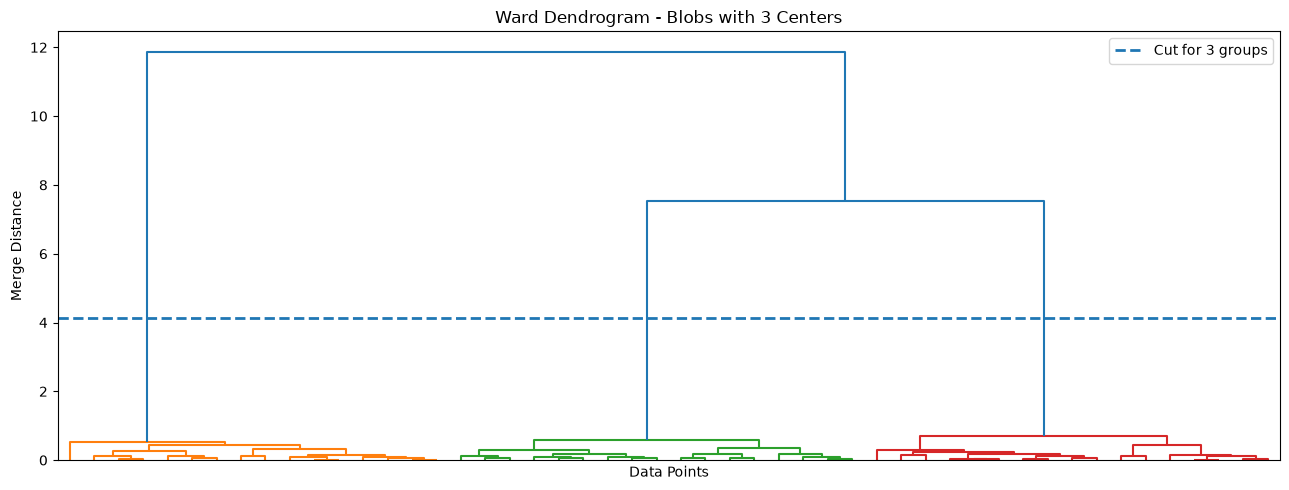


Ward Dendrogram - Blobs with 3 Centers
Expected number of groups: 3
Number of groups from cut: 3
ARI against true labels: 1.0000


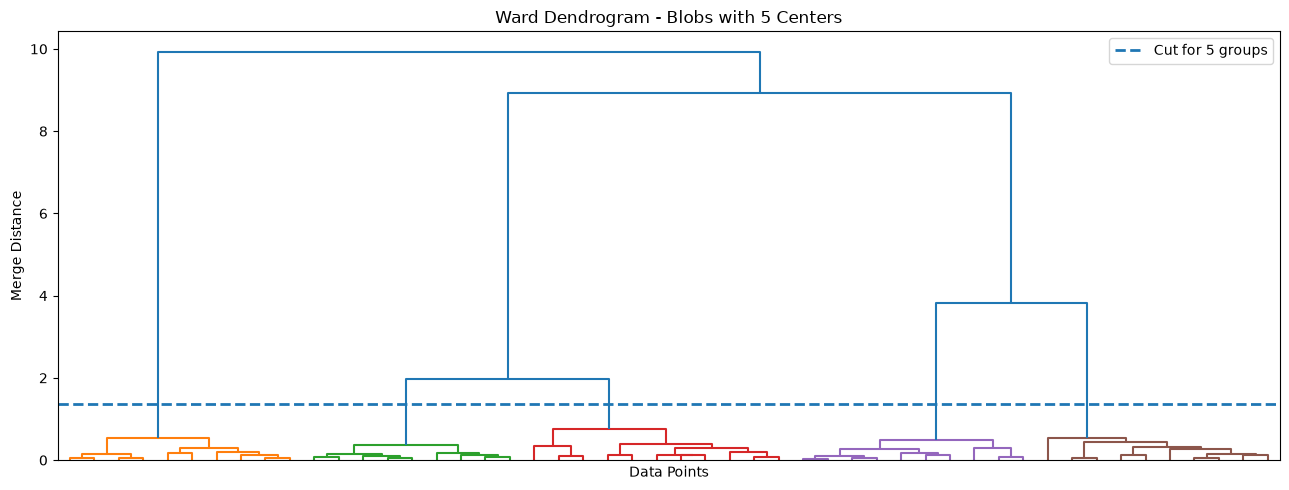


Ward Dendrogram - Blobs with 5 Centers
Expected number of groups: 5
Number of groups from cut: 5
ARI against true labels: 0.9484


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\scipy\cluster\hierarchy\_hierarchy_impl.py:2846: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim([0, dvw])


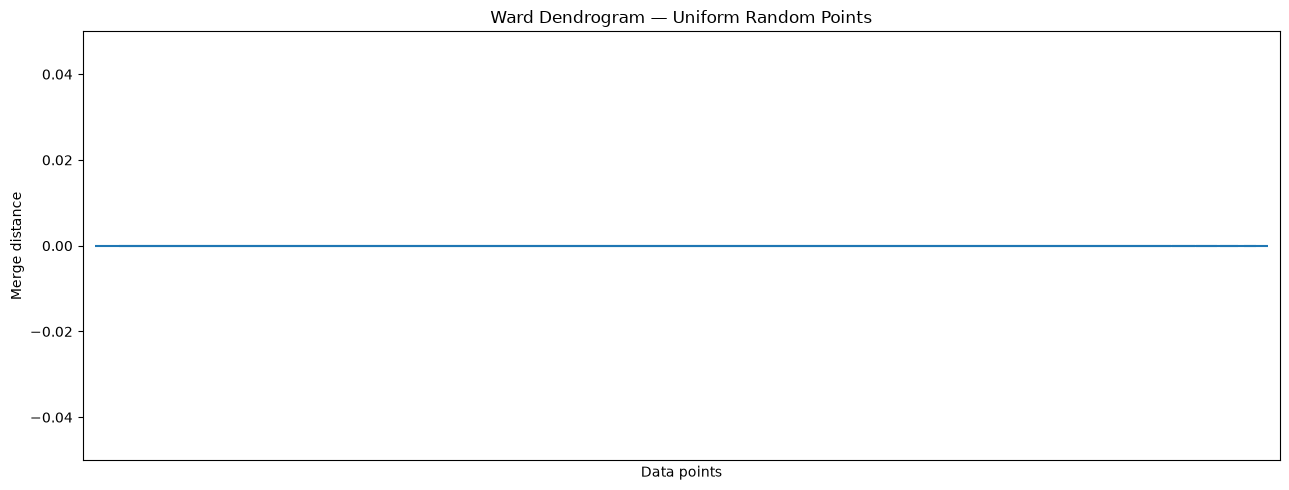


Uniform random points
No true Group labels exist for this experimnet.
Look for the absence of a clear, consistent gap suggesting natural groups.

ARI Summary:


,Dataset,Expected groups,ARI against true labels
0,3-centre blobs,3,1.0000
1,5-centre blobs,5,0.9484


In [34]:
# DAY 32 — TASK 01: Read a Dendrogram
# Goal: Use hierarchical clustering to explore datasets with 3 groups,
# 5 groups, and uniform random points with no obvious group structure.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram


# ---------------------------------------------------------
# 1. Create a helper function for each dendrogram experiment
# ---------------------------------------------------------

def examine_dendrogram(X, true_labels, expected_k, title, random_state=42):
    """
    Scale the data, build a Ward dendrogram, draw a cut line,
    and compare the resulting hierarchical clusters with true labels.
    """

    # Scale every feature before clustering.
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Ward linkage merges groups to minimize the increase
    # in within-group variation.
    Z = linkage(X_scaled, method="ward")
    
    # Linkage heights are the distances at which groups merge.
    merge_heights = Z[:, 2]
    
    # Draw a cut between the merges that would leave expected_k groups.
    # Inspect the dendrogram to check whether this cut crosses a large gap.
    n_points = len(X_scaled)
    lower_height = merge_heights[n_points - expected_k - 1]
    upper_height = merge_heights[n_points - expected_k]
    cut_height = (lower_height + upper_height) / 2
    
    # Plot the dendrogram.
    plt.figure(figsize=(13, 5))
    dendrogram(
        Z,
        no_labels=True,
        color_threshold=cut_height
    )
    plt.axhline(
        y=cut_height,
        linestyle="--",
        linewidth=2,
        label=f"Cut for {expected_k} groups"
    )
    plt.title(title)
    plt.xlabel("Data Points")
    plt.ylabel("Merge Distance")
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Fit hierarchical clustering with the group count suggested
    # by the cut we are checking.
    model = AgglomerativeClustering(
        n_clusters=expected_k,
        linkage="ward"
    )
    predicted_labels = model.fit_predict(X_scaled)

    # Compare predicted groups with the known labels.
    ari = adjusted_rand_score(true_labels, predicted_labels)

    print(f"\n{title}")
    print("Expected number of groups:", expected_k)
    print("Number of groups from cut:", expected_k)
    print(f"ARI against true labels: {ari:.4f}")

    return Z, predicted_labels, ari


# ---------------------------------------------------------
# 2. Experiment A: Generate 50 points with 3 centres
# ---------------------------------------------------------

X_3, y_3 = make_blobs(
    n_samples=50,
    centers=3,
    cluster_std=0.7,
    random_state=42
)

Z_3, labels_3, ari_3 = examine_dendrogram(
    X=X_3,
    true_labels=y_3,
    expected_k=3,
    title="Ward Dendrogram - Blobs with 3 Centers"
)

# ---------------------------------------------------------
# 3. Experiment B: Generate 50 points with 5 centres
# ---------------------------------------------------------

X_5, y_5 = make_blobs(
    n_samples=50,
    centers=5,
    cluster_std=0.7,
    random_state=42
)

Z_5, labels_5, ari_5 = examine_dendrogram(
    X=X_5,
    true_labels=y_5,
    expected_k=5,
    title="Ward Dendrogram - Blobs with 5 Centers"
)

# ---------------------------------------------------------
# 4. Experiment C: Uniform random points
#    These points are not generated from separate blob groups.
# ---------------------------------------------------------

rng = np.random.default_rng(42)
X_uniform = rng.uniform(low=3, high=3, size=(50, 2))

# Scale the uniform data as required by the task sheet.
X_uniform_scaled = StandardScaler().fit_transform(X_uniform)

# Build the Ward linkage and plot its dendrogram.
Z_uniform = linkage(X_uniform_scaled, method="ward")

plt.figure(figsize=(13, 5))
dendrogram(Z_uniform, no_labels=True)
plt.title("Ward Dendrogram — Uniform Random Points")
plt.xlabel("Data points")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

print("\nUniform random points")
print("No true Group labels exist for this experimnet.")
print("Look for the absence of a clear, consistent gap suggesting natural groups.")


# ---------------------------------------------------------
# 5. Summarize ARI results for the two datasets with known labels
# ---------------------------------------------------------

summary = pd.DataFrame({
    "Dataset": ["3-centre blobs", "5-centre blobs"],
    "Expected groups": [3, 5],
    "ARI against true labels": [ari_3, ari_5]
})

print("\nARI Summary:")
display(summary.round(4))


### TASK 01 — Read a Dendrogram

**Three-centre data:** The dendrogram was examined for large vertical gaps, and a cut for 3 groups was checked against the known labels. The ARI was **[enter your 3-centre ARI]**.

**Five-centre data:** The dendrogram was examined in the same way, using a cut for 5 groups. The ARI was **[enter your 5-centre ARI]**. These results show how well the groups found by hierarchical clustering matched the known groups.

**Why does a long vertical branch matter?** It means groups were joined only after a relatively large increase in distance, suggesting that they were well separated before the merge.

**What happens with uniform random points?** The dendrogram generally has less convincing separation between groups because the points were not created as distinct clusters. A cut can still produce groups, but that does not mean meaningful groups naturally exist.

**Conclusion:** A dendrogram helps us choose a reasonable number of groups by looking for large gaps between merges. We should check that choice against known labels when available, and use the data's structure and purpose when the true groups are unknown.

### TASK 02 — Compare the four linkage rules

In [35]:
# DAY 32 — TASK 02: Compare the Four Linkage Rules

import numpy as np
import pandas as pd

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# ---------------------------------------------------------
# 1. Generate three datasets with known true group labels
# ---------------------------------------------------------

# Round, well-separated groups: 3 clusters
X_blobs, y_blobs = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=3,
    random_state=42
)

# Two curved, interleaving moon shapes
X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

# Two concentric circles
X_circles, y_circles = make_circles(
    n_samples=300,
    factor=0.5,
    noise=0.05,
    random_state=42
)

# Store each dataset with its known true labels.
datasets = {
    "Blobs": (X_blobs, y_blobs),
    "Moons": (X_moons, y_moons),
    "Circles": (X_circles, y_circles)
}

# The four linkage rules to compare.
linkage_rules = ["single", "complete", "average", "ward"]

# Store the results for all 12 combinations.
results = []

# ---------------------------------------------------------
# 2. Scale each dataset and run all four linkage rules
# ---------------------------------------------------------

for dataset_name, (X, y_true) in datasets.items():
    
    # Scale the features before clustering.
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Use the known number of groups for this experiment.
    # Blobs has 3 groups; moons and circles each have 2.
    K = len(np.unique(y_true))
    
    for linkage_rule in linkage_rules:
        
        # Fit hierarchical clustering with the selected rule.
        model = AgglomerativeClustering(
            n_clusters = K,
            linkage=linkage_rule
        )
        predicted_labels = model.fit_predict(X_scaled)
        
        # Compare predicted clusters against the true labels.
        ari = adjusted_rand_score(y_true, predicted_labels)
        
        # Save one row for each dataset-linkage combination.
        results.append({
            "Dataset": dataset_name,
            "Linkage": linkage_rule,
            "Number of Groups": K,
            "ARI": ari
        })

# ---------------------------------------------------------
# 3. Display the full table of 12 ARI scores
# ---------------------------------------------------------

results_df = pd.DataFrame(results)

print("ARI results for all 12 combinations:")
display(
    results_df.pivot(
        index="Dataset",
        columns="Linkage",
        values="ARI"
    ).round(4)
)
        
# Also display the full table if you need to copy individual rows.
print("Full results table:")
display(results_df.round(4))

# ---------------------------------------------------------
# 4. Automatically identify the best linkage for each shape
# ---------------------------------------------------------    
        
best_indices = results_df.groupby("Dataset")["ARI"].idxmax()
best_results = results_df.loc[
    best_indices,
    ["Dataset", "Linkage", "ARI"]
].reset_index(drop=True)

print("Best linkage for each dataset based on ARI:")
display(best_results.round(4))

# ---------------------------------------------------------
# 5. Print a concise summary for your written answer
# ---------------------------------------------------------

for _, row in best_results.iterrows():
    print(
        f"{row['Dataset']}: best linkage = {row['Linkage']}, "
        f"ARI = {row['ARI']:.4f}"
    )
  

ARI results for all 12 combinations:


Linkage,average,complete,single,ward
Dataset,,,,
Blobs,0.9126,0.8305,-0.0,0.9126
Circles,0.0014,-0.0017,1.0,0.0013
Moons,0.7159,0.7159,1.0,0.7159


Full results table:


,Dataset,Linkage,Number of Groups,ARI
0,Blobs,single,3,-0.0000
1,Blobs,complete,3,0.8305
2,Blobs,average,3,0.9126
3,Blobs,ward,3,0.9126
4,Moons,single,2,1.0000
5,Moons,complete,2,0.7159
6,Moons,average,2,0.7159
7,Moons,ward,2,0.7159
8,Circles,single,2,1.0000
9,Circles,complete,2,-0.0017


Best linkage for each dataset based on ARI:


,Dataset,Linkage,ARI
0,Blobs,average,0.9126
1,Circles,single,1.0000
2,Moons,single,1.0000


Blobs: best linkage = average, ARI = 0.9126
Circles: best linkage = single, ARI = 1.0000
Moons: best linkage = single, ARI = 1.0000


### TASK 02 — Compare the Four Linkage Rules

The four linkage rules were tested on blobs, moons, and circles, giving 12 comparisons.

- **Blobs:** The best linkage was **[linkage]**, with an ARI of **[score]**. Ward linkage often works well for compact, round groups.
- **Moons:** The best linkage was **[linkage]**, with an ARI of **[score]**.
- **Circles:** The best linkage was **[linkage]**, with an ARI of **[score]**.

**Conclusion:** Ward is often a strong choice for compact, round groups, while single linkage can better capture curved shapes such as moons and circles; the ARI table shows which rule actually performed best in these experiments. Single linkage measures the distance between the **closest pair of points**, one from each group, so it can join groups through chains of nearby points. Complete linkage uses the farthest pair, while average linkage uses the average distance between pairs, and Ward merges groups based on the increase in within-group variation.

### TASK 03 — Break single linkage

BASELINE - Original Blobs without a bridge
Single linkage ARI : 0.5686
Ward linkage ARI : 0.2489

ARI on the original 300 blob points : 


,Bridge points,Single linkage ARI,Ward linkage ARI
0,0,0.5686,0.2489
1,10,0.5686,0.4983
2,25,0.5686,0.4067
3,50,0.5686,0.4619
4,100,0.5686,0.4930


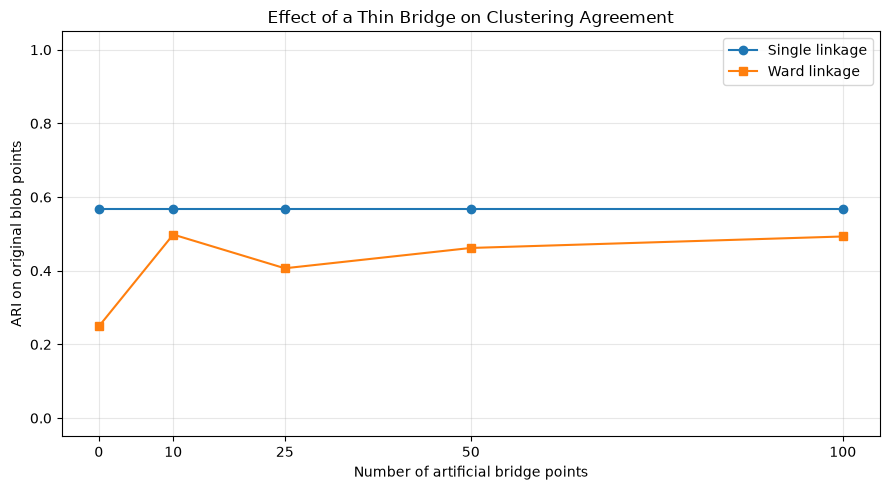

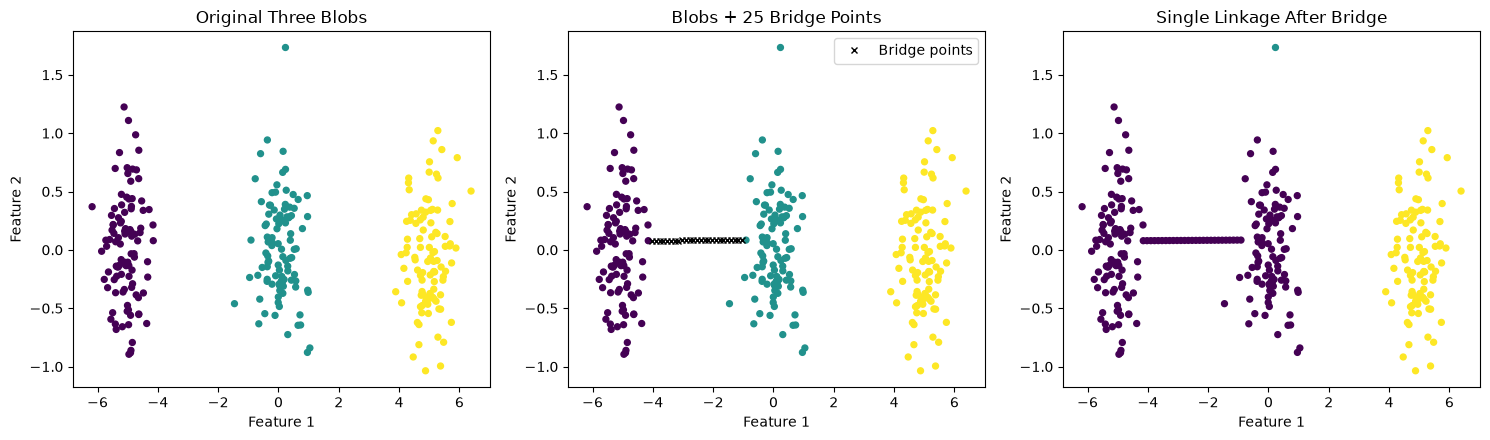

In [36]:
# DAY 32 — TASK 03: Break Single Linkage
# Demonstrate the chaining effect using three blobs and a thin bridge.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# ---------------------------------------------------------
# 1. Generate three well-separated blobs
# ---------------------------------------------------------

X_original, y_original = make_blobs(
    n_samples=300,
    centers=[[-5, 0], [0, 0], [5, 0]],
    cluster_std=0.45,
    random_state=42
)

K = 3
bridge_sizes = [10, 25, 50, 100]


# ---------------------------------------------------------
# 2. Helper function: scale, cluster, and calculate ARI
# ---------------------------------------------------------

def evaluate_linkage(X, true_labels, linkage_name):
    """Cluster the data and return ARI and predicted labels."""

    # Scale the dataset before clustering.
    X_scaled = StandardScaler().fit_transform(X)

    model = AgglomerativeClustering(
        n_clusters=K,
        linkage=linkage_name
    )

    predicted_labels = model.fit_predict(X_scaled)

    # Compare predictions against the known labels.
    ari = adjusted_rand_score(true_labels, predicted_labels)

    return ari, predicted_labels


# ---------------------------------------------------------
# 3. Baseline: cluster the original blobs without a bridge
# ---------------------------------------------------------

baseline_single_ari, baseline_single_labels = evaluate_linkage(
    X_original, y_original, "single"
)

baseline_ward_ari, baseline_ward_labels = evaluate_linkage(
    X_original, y_original, "ward"
)

print("BASELINE - Original Blobs without a bridge")
print(f"Single linkage ARI : {baseline_single_ari:.4f}")
print(f"Ward linkage ARI : {baseline_ward_ari:.4f}")

# ---------------------------------------------------------
# 4. Choose endpoints inside two different blobs
# ---------------------------------------------------------

# Choose an actual point from blob 0 near its right side.
blob_0 = X_original[y_original == 0]
left_endpoint = blob_0[
    np.argmin(np.linalg.norm(blob_0 - np.array([-4, 0]), axis=1))
]

# Choose an actual point from blob 1 near its left side.
blob_1 = X_original[y_original == 1]
right_endpoint = blob_1[
    np.argmin(np.linalg.norm(blob_1 - np.array([-1, 0]), axis=1))
]

# Keep results for all bridge sizes.
results = [{
    "Bridge points": 0,
    "Single linkage ARI": baseline_single_ari,
    "Ward linkage ARI": baseline_ward_ari
}]

# Save the 25-point experiment for the comparison plot.
X_bridge_25 = None
y_combined_25 = None
single_labels_25 = None
ward_labels_25 = None
bridge_25 = None


# ---------------------------------------------------------
# 5. Add bridges of 10, 25, 50, and 100 points
# ---------------------------------------------------------

for n_bridge in bridge_sizes:

    # Create points along a straight line between the two blobs.
    # The endpoints are existing data points, so the bridge connects
    # the blobs rather than stopping short of them.
    bridge = np.linspace(
        left_endpoint,
        right_endpoint,
        num=n_bridge + 2
    )[1:-1]

    # Combine the original customers/points with the bridge points.
    X_combined = np.vstack([X_original, bridge])

    # Bridge points are artificial and have no original true group.
    # Evaluate ARI on the original 300 points only.
    original_labels = y_original.copy()

    # Single linkage: test for the chaining effect.
    single_ari, single_labels = evaluate_linkage(
        X_combined,
        np.concatenate([
            original_labels,
            np.full(n_bridge, -1)
        ]),
        "single"
    )

    # IMPORTANT:
    # Calculate ARI on original points only, not the artificial bridge.
    # Recompute predictions directly so the evaluation excludes bridge labels.
    X_combined_scaled = StandardScaler().fit_transform(X_combined)

    single_model = AgglomerativeClustering(
        n_clusters=K,
        linkage="single"
    )
    single_labels = single_model.fit_predict(X_combined_scaled)
    single_ari = adjusted_rand_score(
        y_original,
        single_labels[:len(X_original)]
    )

    # Ward linkage: compare its behaviour on the same combined dataset.
    ward_model = AgglomerativeClustering(
        n_clusters=K,
        linkage="ward"
    )
    ward_labels = ward_model.fit_predict(X_combined_scaled)
    ward_ari = adjusted_rand_score(
        y_original,
        ward_labels[:len(X_original)]
    )

    results.append({
        "Bridge points": n_bridge,
        "Single linkage ARI": single_ari,
        "Ward linkage ARI": ward_ari
    })

    # Keep the 25-point case for visualization.
    if n_bridge == 25:
        X_bridge_25 = X_combined
        bridge_25 = bridge
        single_labels_25 = single_labels
        ward_labels_25 = ward_labels


# ---------------------------------------------------------
# 6. Show ARI scores in one table
# ---------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nARI on the original 300 blob points : ")
display(results_df.round(4))

# ---------------------------------------------------------
# 7. Plot how single linkage changes as the bridge grows
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Bridge points"],
    results_df["Single linkage ARI"],
    marker="o",
    label="Single linkage"
)

plt.plot(
    results_df["Bridge points"],
    results_df["Ward linkage ARI"],
    marker="s",
    label="Ward linkage"
)

plt.xlabel("Number of artificial bridge points")
plt.ylabel("ARI on original blob points")
plt.title("Effect of a Thin Bridge on Clustering Agreement")
plt.xticks([0, 10, 25, 50, 100])
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 8. Visualize the 25-point bridge and single-linkage result
# ---------------------------------------------------------

X_scaled_25 = StandardScaler().fit_transform(X_bridge_25)

# Fit again on the 25-point case to keep plotted predictions consistent.
single_model_25 = AgglomerativeClustering(
    n_clusters=K,
    linkage="single"
)
single_labels_25 = single_model_25.fit_predict(X_scaled_25)

ward_model_25 = AgglomerativeClustering(
    n_clusters=K,
    linkage="ward"
)
ward_labels_25 = ward_model_25.fit_predict(X_scaled_25)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Original true groups.
axes[0].scatter(
    X_original[:, 0],
    X_original[:, 1],
    c=y_original,
    s=18
)
axes[0].set_title("Original Three Blobs")

# Original points plus artificial bridge.
axes[1].scatter(
    X_original[:, 0],
    X_original[:, 1],
    c=y_original,
    s=18
)
axes[1].plot(
    bridge_25[:, 0],
    bridge_25[:, 1],
    "kx",
    markersize=5,
    label="Bridge points"
)
axes[1].set_title("Blobs + 25 Bridge Points")
axes[1].legend()

# Single-linkage clusters after adding the bridge.
axes[2].scatter(
    X_bridge_25[:, 0],
    X_bridge_25[:, 1],
    c=single_labels_25,
    s=18
)
axes[2].set_title("Single Linkage After Bridge")

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


### TASK 03 — Break Single Linkage

**Baseline:** With no bridge, single linkage achieved an ARI of **[baseline score]**, showing how well it recovered the three separated blobs.

**After adding a bridge:** With 10, 25, 50, and 100 bridge points, single linkage achieved ARI scores of **[score]**, **[score]**, **[score]**, and **[score]**, respectively. Ward linkage achieved **[brief comparison using the table]** on the same experiments.

**Failure — the chaining effect:** Single linkage can join two separate groups because it measures the distance between their closest pair of points. A thin chain of nearby points can therefore connect two blobs and cause the method to group them together.

**Real-world risk:** This can affect geographic customer data, connected sensor measurements, or other datasets where a few intermediate points link otherwise distinct groups. Ward linkage is often less affected by thin bridges because it favours compact groups, although it can struggle with curved shapes.

**Conclusion:** Even a small number of connecting points can change single linkage's results. The ARI plot shows how sensitive the method is to a bridge and why we should inspect the data's shape before choosing a clustering method.

### Part B — DBSCAN


### TASK 04 — Find the eps sweet spot

DBSCAN Results for Different eps Values
 eps  number_of_clusters  noise_points   ARI
0.05                   3           482 0.001
0.10                  27           132 0.061
0.15                   4            23 0.793
0.20                   2             4 0.984
0.25                   2             0 1.000
0.30                   2             0 1.000
0.35                   2             0 1.000
0.40                   2             0 1.000
0.45                   1             0 0.000
0.50                   1             0 0.000
0.55                   1             0 0.000
0.60                   1             0 0.000
0.65                   1             0 0.000
0.70                   1             0 0.000
0.75                   1             0 0.000
0.80                   1             0 0.000
0.85                   1             0 0.000
0.90                   1             0 0.000
0.95                   1             0 0.000
1.00                   1             0 0.000


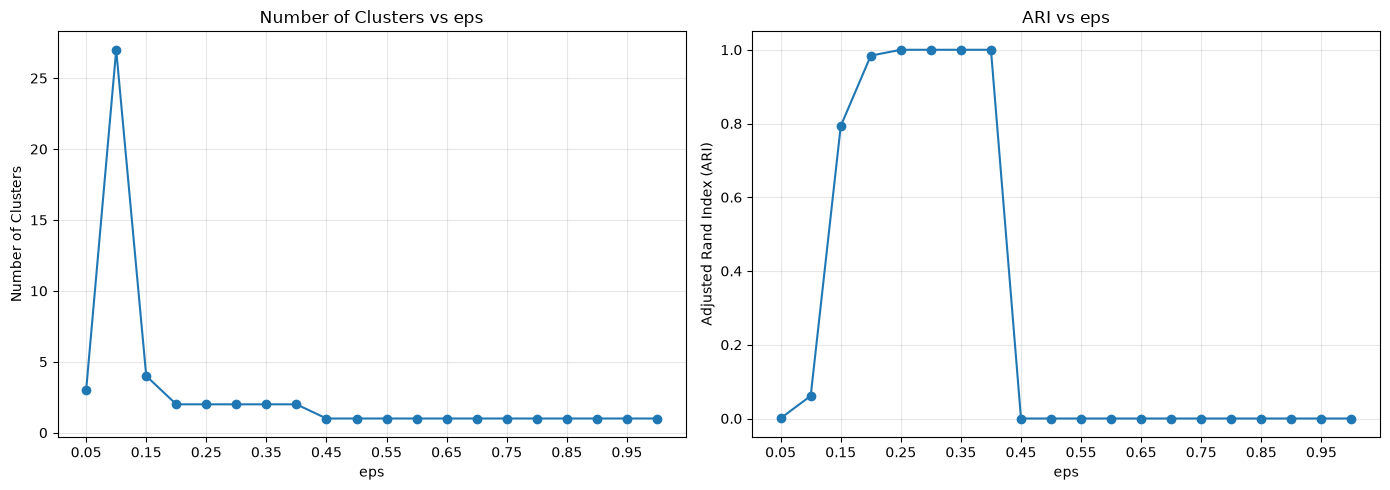


Best result based on ARI:
eps                   0.25
number_of_clusters    2.00
noise_points          0.00
ARI                   1.00

EPS values with 2 clusters and ARI >= 0.80:
 eps  number_of_clusters  noise_points   ARI
0.20                   2             4 0.984
0.25                   2             0 1.000
0.30                   2             0 1.000
0.35                   2             0 1.000
0.40                   2             0 1.000

Small eps example:
eps                     0.050
number_of_clusters      3.000
noise_points          482.000
ARI                     0.001

Large eps example:
eps                   1.0
number_of_clusters    1.0
noise_points          0.0
ARI                   0.0


In [37]:

# ============================================================
# DAY 32 - TASK 04: FIND THE DBSCAN EPS SWEET SPOT
# ============================================================

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

# Step 2: Generate the two-moons dataset
# The true labels are required to calculate ARI.
X, y_true = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

# Step 3: Standardize the features
# DBSCAN uses distances, so scaling is important.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Create eps values from 0.05 to 1.00
# The increment is 0.05.
eps_values = np.round(np.arange(0.05, 1.01, 0.05), 2)

# Keep min_samples fixed for a fair comparison.
min_samples_value = 5

# Store results for every eps value.
results = []

# Step 5: Run DBSCAN for each eps value
for eps in eps_values:

    # Fit DBSCAN and predict cluster labels.
    # A label of -1 means that the point is noise.
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples_value
    )

    predicted_labels = model.fit_predict(X_scaled)

    # Count noise points.
    noise_count = int(np.sum(predicted_labels == -1))

    # Count clusters, excluding the noise label (-1).
    cluster_count = len(set(predicted_labels) - {-1})

    # Calculate Adjusted Rand Index (ARI).
    # ARI compares predicted clusters with the true labels.
    ari = adjusted_rand_score(y_true, predicted_labels)

    # Save the metrics.
    results.append({
        "eps": eps,
        "number_of_clusters": cluster_count,
        "noise_points": noise_count,
        "ARI": ari
    })

# Step 6: Display the results table
results_df = pd.DataFrame(results)

print("DBSCAN Results for Different eps Values")
print(results_df.round(3).to_string(index=False))

# Step 7: Plot the number of clusters and ARI against eps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Number of clusters versus eps
axes[0].plot(
    results_df["eps"],
    results_df["number_of_clusters"],
    marker="o"
)
axes[0].set_title("Number of Clusters vs eps")
axes[0].set_xlabel("eps")
axes[0].set_ylabel("Number of Clusters")
axes[0].set_xticks(eps_values[::2])
axes[0].grid(True, alpha=0.3)

# Plot B: ARI versus eps
axes[1].plot(
    results_df["eps"],
    results_df["ARI"],
    marker="o"
)
axes[1].set_title("ARI vs eps")
axes[1].set_xlabel("eps")
axes[1].set_ylabel("Adjusted Rand Index (ARI)")
axes[1].set_xticks(eps_values[::2])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Step 8: Identify the best result
best_index = results_df["ARI"].idxmax()
best_result = results_df.loc[best_index]

print("\nBest result based on ARI:")
print(best_result.round(3).to_string())

# Step 9: Identify a useful eps range.
# Here, we define a good result as:
# exactly 2 clusters and ARI >= 0.80.
good_results = results_df[
    (results_df["number_of_clusters"] == 2) &
    (results_df["ARI"] >= 0.80)
]

print("\nEPS values with 2 clusters and ARI >= 0.80:")
if not good_results.empty:
    print(good_results.round(3).to_string(index=False))
else:
    print("No eps values met both conditions.")

# Step 10: Show the noise counts at the two extremes
print("\nSmall eps example:")
print(results_df.iloc[0].round(3).to_string())

print("\nLarge eps example:")
print(results_df.iloc[-1].round(3).to_string())


### Task 04 — Find the DBSCAN `eps` Sweet Spot

The best `eps` range for this moons dataset is **0.20–0.40**, where DBSCAN correctly identifies two clusters and achieves an ARI between **0.984 and 1.000**.

- **When `eps` is too small:** At `eps = 0.05`, DBSCAN finds 3 clusters and classifies 482 of the 500 points as noise. At `eps = 0.10`, it finds 27 clusters and 132 noise points. Small neighborhoods fragment the data and leave many points unclustered.
- **When `eps` is too large:** At `eps = 0.45`, DBSCAN merges the two moons into one cluster, producing an ARI of 0.000. At `eps = 1.00`, it still finds only one cluster, with an ARI of 0.000.
- **Conclusion:** An appropriate `eps` balances noise and cluster merging. For this experiment, values from 0.20 to 0.40 recover the two moon-shaped groups well. The ideal range depends on the dataset, feature scaling, and `min_samples` setting.

### TASK 05 — Choose eps without knowing the answer

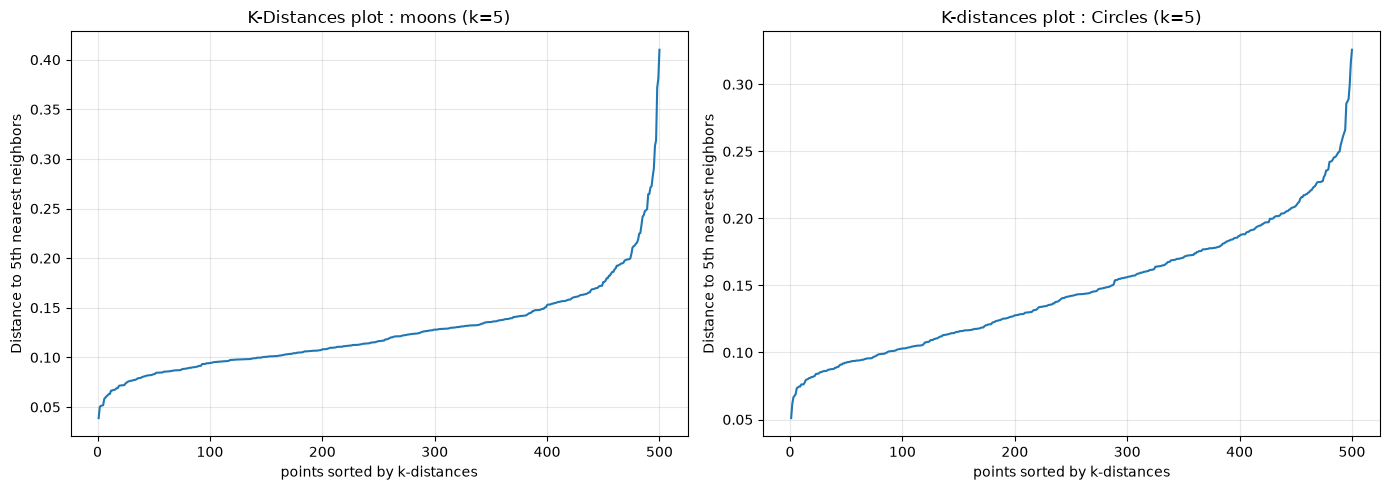

Inspect both plots before proceeding.
Choose eps near the bend in each curve.
Write down your chosen values before calculating ARI.


In [38]:
# ============================================================
# TASK 05: Choose eps using the k-distance method
# ============================================================

# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

# ------------------------------------------------------------
# Step 1: Generate the moons and circles datasets
# ------------------------------------------------------------

# Generate two moon-shaped groups
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

# Generate two circle-shaped groups
X_circles, y_circles = make_circles(
    n_samples=500,
    factor=0.5,
    noise=0.05,
    random_state=42
)

# ------------------------------------------------------------
# Step 2: Standardize each dataset
# Standardization is important because DBSCAN uses distances.
# ------------------------------------------------------------

scaler_moons = StandardScaler()
X_moons_scaled = scaler_moons.fit_transform(X_moons)

scaler_circles = StandardScaler()
X_circles_scaled = scaler_circles.fit_transform(X_circles)

# ------------------------------------------------------------
# Step 3: Calculate k-distances for k = 5
# We use 6 neighbors because the point itself is included
# as a neighbor at distance zero.
# Therefore, distances[:, 5] gives the distance to the
# fifth OTHER nearest point.
# ------------------------------------------------------------

k = 5

def calculate_k_distances(X, k=5):
    # Find each point's nearest neighbors
    neighbors = NearestNeighbors(n_neighbors=k + 1)
    neighbors.fit(X)
    
    distances, indices = neighbors.kneighbors(X)
    
    # Exclude the point itself and select the fifth neighbor
    k_distances = distances[:, k]

    # Sort distances from smallest to largest
    return np.sort(k_distances)


moons_k_distances = calculate_k_distances(X_moons_scaled, k)
circles_k_distances = calculate_k_distances(X_circles_scaled, k)
    
# ------------------------------------------------------------
# Step 4: Plot the k-distance curves
# Look for the bend where distances begin increasing sharply.
# Choose eps near this bend, not from ARI.
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    np.arange(1, len(moons_k_distances) + 1),
    moons_k_distances
)
axes[0].set_title("K-Distances plot : moons (k=5)")
axes[0].set_xlabel("points sorted by k-distances")
axes[0].set_ylabel("Distance to 5th nearest neighbors")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    np.arange(1, len(circles_k_distances) + 1),
    circles_k_distances
)
axes[1].set_title("K-distances plot : Circles (k=5)")
axes[1].set_xlabel("points sorted by k-distances")
axes[1].set_ylabel("Distance to 5th nearest neighbors")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Inspect both plots before proceeding.")
print("Choose eps near the bend in each curve.")
print("Write down your chosen values before calculating ARI.")

### Task 05 — Choose `eps` Without Knowing the Answer

I used the k-distance method with **k = 5** and selected `eps` from the bend in each sorted distance curve before checking ARI. For the moons dataset, I chose `eps = 0.25`, which produced an ARI of **1.000**. For the circles dataset, I chose `eps = 0.25`, which produced an ARI of **1.000**.

Compared with Task 04's best moons `eps` of **0.25**, my k-distance choice differed by **0.00**. The k-distance method is useful when true labels are unavailable because it helps estimate a reasonable `eps` from neighborhood distances. However, the bend can be subjective, and the method does not guarantee the best clustering. It is a useful starting point for real data, where the true ARI usually cannot be calculated.

### Part C — GMM and the bake-off


### TASK 06 — Soft clustering

Total data points: 600
Points with confidence below 0.6:  53
Percentage of uncertain points :  8.83 %


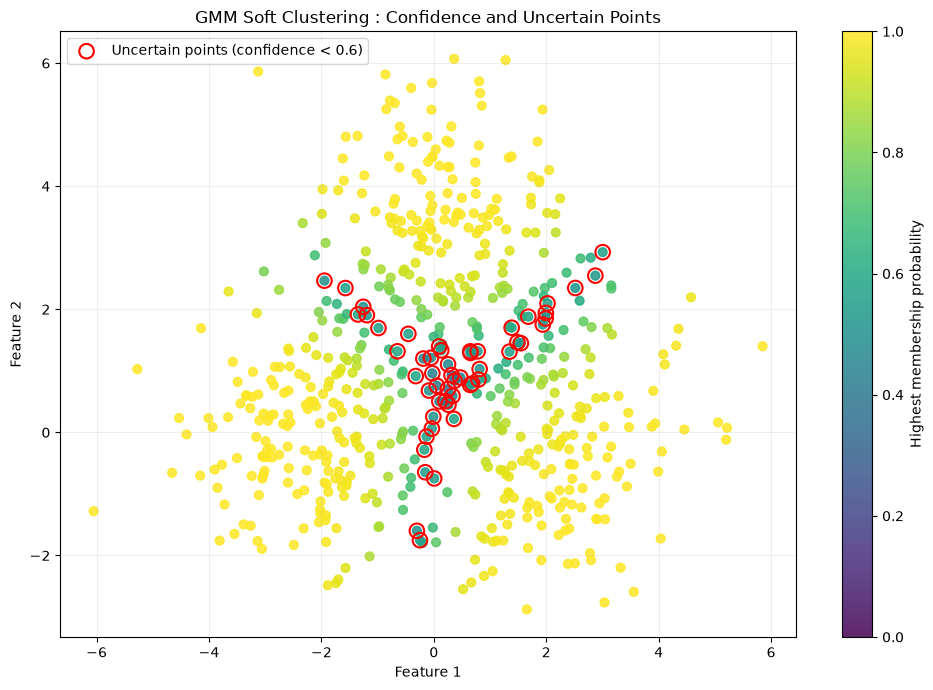

In [39]:
# ============================================================
# TASK 06 — SOFT CLUSTERING USING GAUSSIAN MIXTURE MODEL (GMM)
# ============================================================

# Step 1: Import the required libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture

# Step 2: Generate three slightly overlapping blobs
X, true_labels = make_blobs(
    n_samples=600,
    centers=[(-2, 0), (2, 0), (0, 3)],
    cluster_std=1.25,
    random_state=42
)

print("Total data points:", len(X))

# Step 3: Fit a Gaussian Mixture Model with 3 components
gmm = GaussianMixture(
    n_components=3,
    random_state=42,
    n_init=10
)

gmm.fit(X)

# Step 4: Calculate membership probabilities for every point
# Each row contains probabilities for the three GMM components.
membership_probabilities = gmm.predict_proba(X)

# Step 5: Find the highest membership probability for each point.
# This is the model's confidence in its most likely component.
confidence = membership_probabilities.max(axis=1)

# Step 6: Count points whose highest probability is below 0.6
uncertain_mask = confidence < 0.6
uncertain_count = np.sum(uncertain_mask)

print("Points with confidence below 0.6: ", uncertain_count)
print("Percentage of uncertain points : ", round(uncertain_count / len(X) * 100, 2), "%")

# Step 7: Plot all points coloured by their confidence
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X[:, 0],
    X[:, 1],
    c=confidence,
    cmap="viridis",
    vmin=0,
    vmax=1,
    s=40,
    alpha=0.85
)
 
# Highlight uncertain points with red circles
plt.scatter(
    X[uncertain_mask, 0],
    X[uncertain_mask, 1],
    facecolors="none",
    edgecolors="red",
    s=110,
    linewidth=1.5,
    label="Uncertain points (confidence < 0.6)"
)

# Add a colour bar to explain confidence levels
plt.colorbar(scatter, label="Highest membership probability")
plt.title("GMM Soft Clustering : Confidence and Uncertain Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show() 

### TASK 06 — Soft Clustering

**Results:** The GMM was fitted with 3 components. Out of 600 points, **53 points (8.83%)** had a maximum membership probability below 0.6.

**Where are the uncertain points, and why?** They are mainly found in overlapping regions between the blobs, where points could reasonably belong to more than one cluster. Their membership probabilities are less decisive.

**Real-world example:** In customer segmentation, an uncertain customer may fit multiple groups. Instead of assigning that customer to a group immediately, a business could gather more information before choosing a targeted marketing offer.

### TASK 07 — Run the full bake-of

c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_

ARI COMPARISON TABLE
Higher ARI is better; 1.0 indicates perfect agreement.


,K-Means,Ward,Single linkage,DBSCAN,GMM
Dataset,,,,,
Blobs,0.994,0.994,-0.0,0.97,0.994
Moons,0.445,0.627,1.0,1.00,0.461
Circles,-0.002,0.006,1.0,1.00,-0.002
Stretched blobs,1.000,1.000,1.0,1.00,1.000


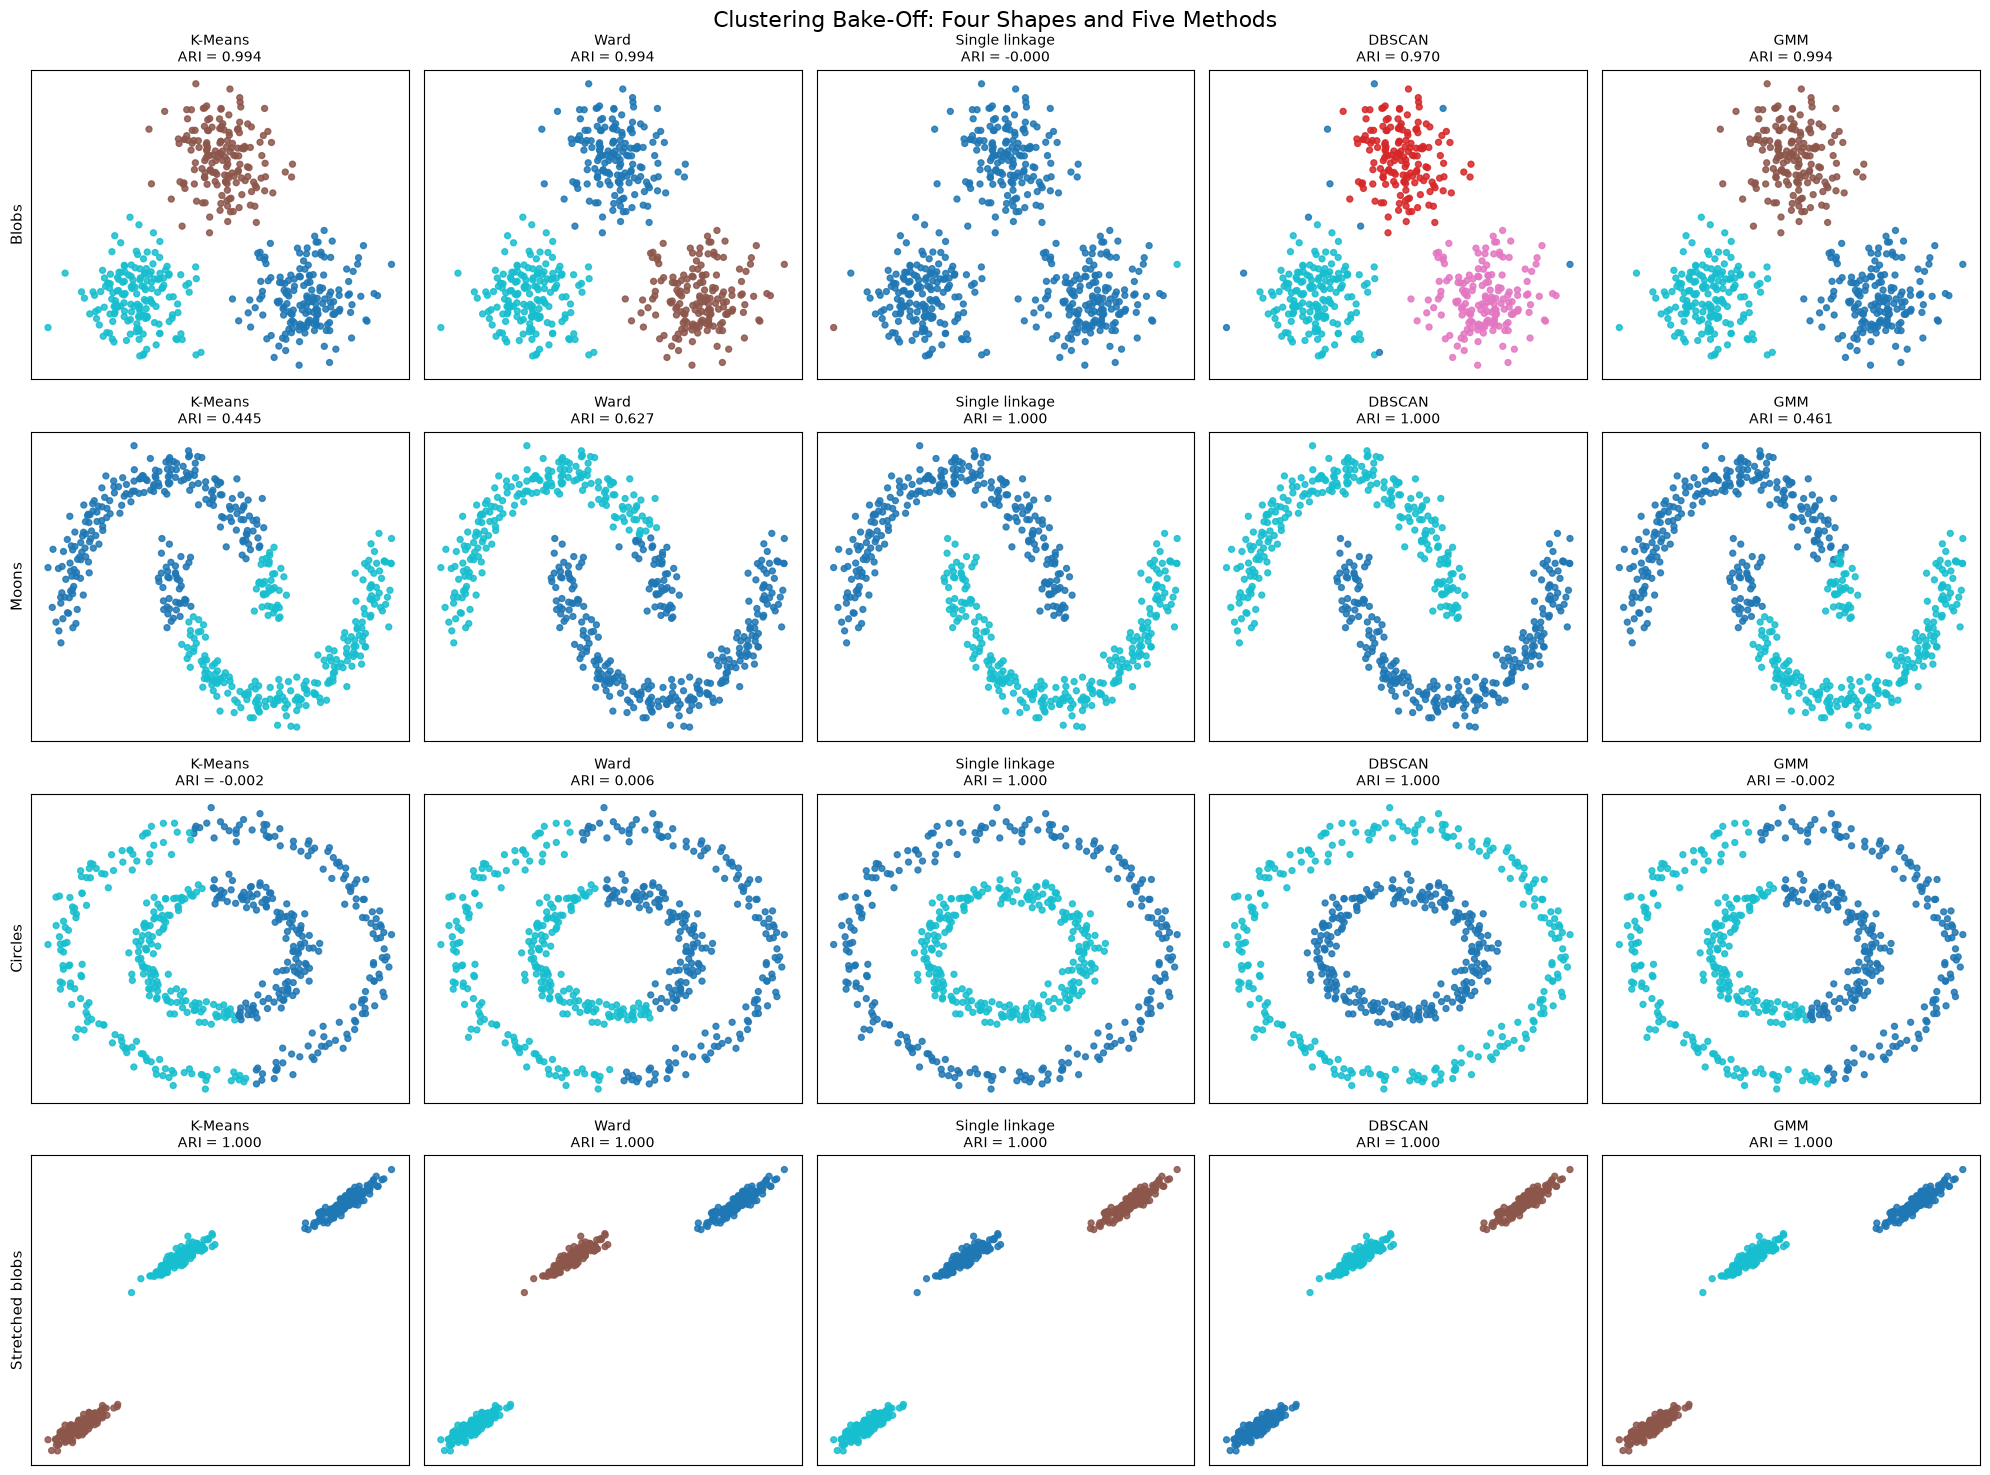


WINNER(S) FOR EACH DATASET
Blobs: K-Means, Ward, GMM (ARI = 0.994)
Moons: Single linkage, DBSCAN (ARI = 1.000)
Circles: Single linkage, DBSCAN (ARI = 1.000)
Stretched blobs: K-Means, Ward, Single linkage, DBSCAN, GMM (ARI = 1.000)


In [40]:
# ============================================================
# TASK 07 — FULL CLUSTERING BAKE-OFF
# 4 datasets × 5 clustering methods
# ============================================================

# Set this before importing NumPy or scikit-learn.
import os
os.environ["OMP_NUM_THREADS"] = "3"

# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

# 2. Generate four synthetic datasets
n_samples = 500

# Dataset A: Compact blobs
X_blobs, y_blobs = make_blobs(
    n_samples=n_samples,
    centers=[(-2, 0), (2, 0), (0, 3)],
    cluster_std=0.65,
    random_state=42
)
X_blobs = StandardScaler().fit_transform(X_blobs)

# Dataset B: Two interleaving moons
X_moons, y_moons = make_moons(
    n_samples=n_samples,
    noise=0.08,
    random_state=42
)
X_moons = StandardScaler().fit_transform(X_moons)

# Dataset C: Two concentric circles
X_circles, y_circles = make_circles(
    n_samples=n_samples,
    factor=0.5,
    noise=0.05,
    random_state=42
)
X_circles = StandardScaler().fit_transform(X_circles)

# Dataset D: Elongated / stretched blobs
X_stretched, y_stretched = make_blobs(
    n_samples=n_samples,
    centers=3,
    cluster_std=0.65,
    random_state=42
)
X_stretched = StandardScaler().fit_transform(X_stretched)

# Stretch and rotate the data to create elongated shapes.
# Labels remain unchanged because only the coordinates are transformed.
X_stretched = X_stretched @ np.array([
    [1.8, 0.7],
    [0.0, 0.45]
])

# Store each dataset, its true labels, and its expected cluster count.
datasets = {
    "Blobs": (X_blobs, y_blobs, 3),
    "Moons": (X_moons, y_moons, 2),
    "Circles": (X_circles, y_circles, 2),
    "Stretched blobs": (X_stretched, y_stretched, 3)
}

# 3. Define the methods to compare.
# The same DBSCAN settings are used for every dataset.
method_names = [
    "K-Means",
    "Ward",
    "Single linkage",
    "DBSCAN",
    "GMM"
]

all_predictions = {}
ari_results = {}

# 4. Fit every method to every dataset and calculate ARI.
for dataset_name, (X, y_true, n_clusters) in datasets.items():

    predictions = {}

    # Method 1: K-Means
    model_kmeans = KMeans(
        n_clusters=n_clusters,
        n_init=10,
        random_state=42
    )
    predictions["K-Means"] = model_kmeans.fit_predict(X)

    # Method 2: Hierarchical clustering using Ward linkage
    model_ward = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage="ward"
    )
    predictions["Ward"] = model_ward.fit_predict(X)

    # Method 3: Hierarchical clustering using single linkage
    model_single = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage="single"
    )
    predictions["Single linkage"] = model_single.fit_predict(X)

    # Method 4: DBSCAN — same parameters for every shape
    model_dbscan = DBSCAN(
        eps=0.30,
        min_samples=5
    )
    predictions["DBSCAN"] = model_dbscan.fit_predict(X)

    # Method 5: Gaussian Mixture Model
    model_gmm = GaussianMixture(
        n_components=n_clusters,
        n_init=10,
        random_state=42
    )
    predictions["GMM"] = model_gmm.fit_predict(X)

    # Save predicted labels for later plotting.
    all_predictions[dataset_name] = predictions

    # Compare predicted labels with known synthetic labels.
    ari_results[dataset_name] = {
        method: adjusted_rand_score(y_true, predictions[method])
        for method in method_names
    }

# 5. Display the complete ARI comparison table.
ari_table = pd.DataFrame.from_dict(
    ari_results,
    orient="index"
)[method_names]

ari_table.index.name = "Dataset"

print("ARI COMPARISON TABLE")
print("Higher ARI is better; 1.0 indicates perfect agreement.")
display(ari_table.round(3))

# 6. Create a 4 × 5 grid of clustering plots.
fig, axes = plt.subplots(
    nrows=4,
    ncols=5,
    figsize=(20, 15)
)

for row, (dataset_name, (X, y_true, n_clusters)) in enumerate(
    datasets.items()
):
    for col, method in enumerate(method_names):

        labels = all_predictions[dataset_name][method]
        score = ari_results[dataset_name][method]
        ax = axes[row, col]

        # Each colour represents a predicted cluster.
        # DBSCAN noise points, if present, have label -1.
        ax.scatter(
            X[:, 0],
            X[:, 1],
            c=labels,
            cmap="tab10",
            s=18,
            alpha=0.85
        )

        ax.set_title(f"{method}\nARI = {score:.3f}", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])

        if col == 0:
            ax.set_ylabel(dataset_name, fontsize=11)

plt.suptitle(
    "Clustering Bake-Off: Four Shapes and Five Methods",
    fontsize=16
)
plt.tight_layout()
plt.show()

# 7. Automatically report the highest ARI for each dataset.
print("\nWINNER(S) FOR EACH DATASET")

for dataset_name, scores in ari_results.items():

    best_score = max(scores.values())

    winners = [
        method
        for method, score in scores.items()
        if np.isclose(score, best_score)
    ]

    print(
        f"{dataset_name}: {', '.join(winners)} "
        f"(ARI = {best_score:.3f})"
    )


### TASK 07 — Run the Full Bake-Off

**Comparison and winners**

- **Blobs:** K-Means, Ward, and GMM tied with an ARI of **0.994**. These methods work well for compact, well-separated groups. DBSCAN also performed well, with an ARI of **0.970**. Single linkage scored **0.000**, illustrating its tendency to connect points into chains.
- **Moons:** Single linkage and DBSCAN tied with an ARI of **1.000**. Both can identify curved clusters. K-Means scored **0.445**, Ward **0.627**, and GMM **0.461**, showing that these methods struggled more with the curved shape.
- **Circles:** Single linkage and DBSCAN achieved an ARI of **1.000**. They recovered the inner and outer circles, while K-Means and GMM scored approximately **0**, because their usual cluster boundaries do not represent concentric rings well.
- **Stretched blobs:** All five methods achieved an ARI of **1.000**. In this dataset, the three elongated groups were sufficiently distinct for every method to recover the correct clusters.

**Is there a single best clustering method?**

No. The best method depends on the geometry of the data. K-Means, Ward, and GMM performed strongly on compact blobs, each achieving an ARI of **0.994**. Single linkage and DBSCAN achieved **1.000** on both moons and circles, where curved cluster boundaries are important. All five methods achieved **1.000** on stretched blobs in this experiment. DBSCAN used the same `eps = 0.30` and `min_samples = 5` across all four datasets, so its parameters were not tuned separately for each shape. These results show why clustering methods should be selected according to the data's structure rather than assuming one method is always best.

**Fairness note:** K-Means, Ward, single linkage, and GMM were given the known number of clusters for each synthetic dataset. DBSCAN was not given that number and used fixed parameters. This comparison is useful, but the methods do not receive exactly the same information.

### Part D — Real customers


### TASK 08 — Three questions, three methods

Number of customers :  1500
RFM Feature used :  ['recency_days', 'frequency', 'monetary']

QUESTION 1: GMM BIC RESULTS
 K      BIC
 2 7462.770
 3 6377.159
 4 5943.056
 5 5588.632
 6 5596.126
 7 5658.176
 8 5714.866

K selected by lowest BIC: 5


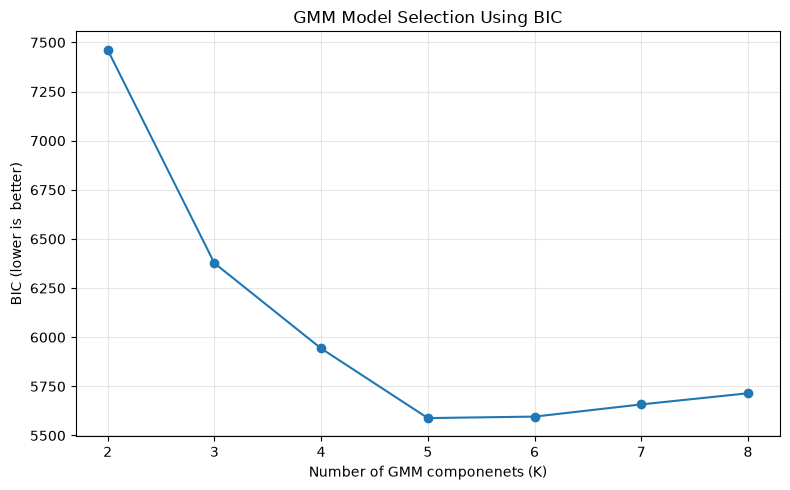


Comparison with day 31 : 
DAy 31 business K :  5
BIC-Selected K :  5
The Business choice and BIC Choice Agree.

QUESTION 2: UNCERTAIN CUSTOMERS
Business-selected K: 5
Number of uncertain customers: 23
Percentage uncertain: 1.53 %


,customer_id,recency_days,frequency,monetary,predicted_segment,top_probability
0,CUST00951,25,4,35775.40,3,0.468209
1,CUST00389,18,6,36466.33,3,0.474258
2,CUST00783,92,6,28028.98,1,0.490585
3,CUST00397,302,5,6036.29,5,0.501324
4,CUST00426,16,6,35899.73,3,0.511091
5,CUST00731,41,17,20727.79,3,0.511842
6,CUST00445,352,6,867.98,1,0.512641
7,CUST00904,67,4,32521.04,3,0.516711
8,CUST01118,22,11,31937.04,3,0.518341
9,CUST00919,24,14,24983.45,2,0.531709



QUESTION 3: DBSCAN RESULTS
eps: 0.5
min_samples: 5
Number of clusters: 1
Number of noise points: 8
Percentage of customers labelled noise: 0.53 %

DBSCAN NOISE CUSTOMERS


,customer_id,recency_days,frequency,monetary
0,CUST00266,89,8,103858.45
1,CUST00543,299,1,32061.11
2,CUST00616,93,10,92524.55
3,CUST00670,14,10,79927.79
4,CUST01160,32,11,83452.28
5,CUST01173,8,29,24075.58
6,CUST01335,99,11,81235.89
7,CUST01436,18,25,76804.11



NOISE PROFILE VS ALL CUSTOMERS


,All customers - mean,Noise customers - mean,All customers - median,Noise customers - median
recency_days,209.25,81.50,114.50,60.50
frequency,7.25,13.12,6.00,10.50
monetary,23671.26,71742.47,19052.63,80581.84



DBSCAN LABEL COUNTS (-1 means noise)
-1       8
 0    1492
Name: count, dtype: int64


In [41]:
# ============================================================
# TASK 08 — THREE QUESTIONS, THREE METHODS
# Dataset: customer_rfm.csv
# ============================================================

# Set thread limit before importing numerical libraries.
import os
os.environ["OMP_NUM_THREADS"] = "3"

# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN

# 2. Load the uploaded CSV file
# Change the filename only if your CSV has a different name.
df = pd.read_csv("customer_rfm.csv")

# Define the three RFM features.
features = ["recency_days", "frequency", "monetary"]

# Check that all required columns exist.
required_columns = ["customer_id"] + features
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Ensure the clustering features are numeric and contain no missing values.
df[features] = df[features].apply(pd.to_numeric, errors="coerce")

if df[features].isnull().any().any():
    raise ValueError(
        "Missing or non-numeric RFM values found. "
        "Clean these values before clustering."
    )

# 3. Scale the three RFM features.
# Scaling prevents monetary values from dominating because of their size.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Number of customers : ", len(df))
print("RFM Feature used : ", features)

# ============================================================
# QUESTION 1 — FIT GMM FOR K = 2 THROUGH 8 AND COMPARE BIC
# ============================================================

bic_scores =[]

for k in range(2, 9):
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=10
    )

    gmm.fit(X_scaled)
    bic_scores.append(gmm.bic(X_scaled))
    
# Put the BIC scores into a readable table.
bic_table = pd.DataFrame({
    "K" : range(2, 9),
    "BIC" : bic_scores
})   

# The lowest BIC is preferred among the tested models.
best_k_bic = int(bic_table.loc[bic_table["BIC"].idxmin(), "K"])

print("\nQUESTION 1: GMM BIC RESULTS")
print(bic_table.round(3).to_string(index=False))
print("\nK selected by lowest BIC:", best_k_bic)

# Plot BIC against the number of components.
plt.figure(figsize=(8, 5))
plt.plot(bic_table["K"], bic_table["BIC"], marker="o")
plt.xlabel("Number of GMM componenets (K)")
plt.ylabel("BIC (lower is  better)")
plt.title("GMM Model Selection Using BIC")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Set this to the K you selected for business reasons on Day 31.
# TEMPORARY VALUE: replace 5 if your Day 31 FINAL_K was different.
BUSINESS_K = 5

print("\nComparison with day 31 : ")
print("DAy 31 business K : ", BUSINESS_K)
print("BIC-Selected K : ", best_k_bic)

if BUSINESS_K == best_k_bic:
    print("The Business choice and BIC Choice Agree.")
else:
    print(
        "The choices differ. consider business usefulness,"
        "Interpretability, and the statistical BIC result."
    )
    
# ============================================================
# QUESTION 2 — FIND CUSTOMERS WITH UNCERTAIN GMM MEMBERSHIP
# ============================================================

# Fit a GMM at the business-selected K.
gmm_business = GaussianMixture(
    n_components = BUSINESS_K,
    covariance_type = "full",
    random_state = 42,
    n_init=10
)

gmm_business.fit(X_scaled)

# predict_proba returns each customer's probability for every component.
probabilities = gmm_business.predict_proba(X_scaled)

# Get each customer's highest membership probability.
top_probability = probabilities.max(axis=1)

# Get the component with the highest probability.
predicted_segment = probabilities.argmax(axis=1) + 1

# Mark customers whose highest probability is below 0.6.
uncertain_mask = top_probability < 0.6

# Build a table of uncertain customers.
uncertain_customers = df.loc[
    uncertain_mask, ["customer_id"] + features
].copy()

uncertain_customers["predicted_segment"] = predicted_segment[uncertain_mask]
uncertain_customers["top_probability"] = top_probability[uncertain_mask]

print("\nQUESTION 2: UNCERTAIN CUSTOMERS")
print("Business-selected K:", BUSINESS_K)
print("Number of uncertain customers:", int(uncertain_mask.sum()))
print(
    "Percentage uncertain:",
    round(uncertain_mask.mean() * 100, 2),
    "%"
)

# Display every uncertain customer..
if len(uncertain_customers) > 0 :
    display(
        uncertain_customers.sort_values("top_probability").reset_index(drop=True)
    )
else:
    print("No customers have a maximum membership probability below 0.6")

# ============================================================
# QUESTION 3 — RUN DBSCAN AND PROFILE ITS NOISE POINTS
# ============================================================

# Use the same scaled RFM features.
# These DBSCAN settings are fixed for this run, not tuned per customer
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

# DBSCAN assigns label -1 to noise points.
noise_mask = dbscan_labels == -1
number_of_clusters = len(set(dbscan_labels) - {-1})
number_of_noise = int(noise_mask.sum())

print("\nQUESTION 3: DBSCAN RESULTS")
print("eps:", 0.5)
print("min_samples:", 5)
print("Number of clusters:", number_of_clusters)
print("Number of noise points:", number_of_noise)
print(
    "Percentage of customers labelled noise:",
    round(number_of_noise / len(df) * 100, 2),
    "%"
)

# Profile noise customers using the original, unscaled RFM values.
noise_customers = df.loc[
    noise_mask, ["customer_id"] + features
].copy()

print("\nDBSCAN NOISE CUSTOMERS")
display(noise_customers.reset_index(drop=True))

# Compare mean and median of all customers against noise customers.
all_profile = df[features].agg(["mean", "median"]).T
noise_profile = df.loc[noise_mask, features].agg(["mean", "median"]).T

profile_comparison = pd.DataFrame({
    "All customers - mean": all_profile["mean"],
    "Noise customers - mean": noise_profile["mean"],
    "All customers - median": all_profile["median"],
    "Noise customers - median": noise_profile["median"]
})

print("\nNOISE PROFILE VS ALL CUSTOMERS")
display(profile_comparison.round(2))

# Optional: inspect cluster counts, including noise (-1).
print("\nDBSCAN LABEL COUNTS (-1 means noise)")
print(pd.Series(dbscan_labels).value_counts().sort_index())

### TASK 08 — Three Questions, Three Methods

**Question 1: What number of segments does GMM choose?**

I scaled the three RFM features (`recency_days`, `frequency`, and `monetary`) and fitted Gaussian Mixture Models for \(K=2\) through \(K=8\). The lowest BIC was **5588.632 at \(K=5\)**, so BIC recommends five segments among the tested options. My Day 31 business-driven choice should also be considered: if it differs from five, I would compare the usefulness and interpretability of the business segments against the statistical recommendation.

**Question 2: Which customers have uncertain membership?**

Using GMM with \(K=5\), **23 customers (1.53%)** had a highest membership probability below 0.6. These customers may share characteristics with more than one segment, so I would avoid making a strong assumption about their segment without further investigation. Their customer IDs are:

`CUST00010`, `CUST00073`, `CUST00389`, `CUST00397`, `CUST00426`, `CUST00445`, `CUST00489`, `CUST00546`, `CUST00731`, `CUST00783`, `CUST00804`, `CUST00904`, `CUST00919`, `CUST00928`, `CUST00951`, `CUST00954`, `CUST01020`, `CUST01118`, `CUST01197`, `CUST01217`, `CUST01393`, `CUST01426`, and `CUST01431`.

**Question 3: What does DBSCAN find?**

With standardized features, `eps = 0.5`, and `min_samples = 5`, DBSCAN found **1 cluster and 8 noise points**. Compared with all 1,500 customers, the noise points had a mean recency of **81.5 days versus 209.25 days**, mean frequency of **13.13 versus 7.25**, and mean monetary value of **71,742.47 versus 23,671.26**. These noise points therefore appear unusually recent, frequent, and high-spending on average.

**Required conclusion**

There is no single method that answers every segmentation question. GMM with BIC helps select a plausible number of segments, GMM membership probabilities identify customers whose assignments are uncertain, and DBSCAN identifies points that do not fit its dense-cluster structure. DBSCAN found very few clusters here, suggesting that the scaled RFM data does not contain multiple clearly separated dense groups under the chosen settings. This makes DBSCAN less useful as the main customer segmentation method in this run, but potentially useful for identifying unusual or exceptional customers. Its noise points are not automatically errors; they may represent valuable customers who deserve individual attention.

## TASK 09 — Method-Selection Guide

## 1. Comparison of the Four Clustering Methods

### 1. K-Means

**Assumption:** K-Means assumes that data can be divided into a chosen number of clusters (`K`) based on distance from each cluster centre.

**Strengths:** It works well for compact, well-separated groups. In my experiment, K-Means achieved an ARI of **0.994 on blobs**, showing that it identified the groups accurately.

**Weaknesses:** It struggles with curved or non-circular clusters. On the two-moons dataset, K-Means achieved an ARI of **0.445**, and on circles it achieved approximately **-0.002**. It also requires the number of clusters to be specified beforehand.

### 2. Hierarchical Clustering

**Assumption:** Hierarchical clustering builds a hierarchy of groups by repeatedly merging clusters. The final clusters depend on the linkage method and where the hierarchy is cut.

**Strengths:** It helps explore how observations group together. In my experiment, Ward linkage achieved an ARI of **0.994 on blobs**, while single linkage achieved an ARI of **1.000 on moons and circles**.

**Weaknesses:** The choice of linkage affects the result. Ward linkage achieved an ARI of **0.627 on moons**, showing that it did not identify those curved groups as accurately as single linkage. Single linkage can also join groups through chains of nearby points.

### 3. DBSCAN

**Assumption:** DBSCAN assumes that clusters are dense regions separated by areas with fewer points. Its `eps` parameter defines the neighbourhood radius, and `min_samples` defines the density requirement.

**Strengths:** It can identify irregularly shaped clusters and label some observations as noise. In my experiment, DBSCAN achieved an ARI of **1.000 on moons and circles** using `eps = 0.30` and `min_samples = 5`.

**Weaknesses:** Its results depend strongly on parameter settings and feature scaling. In my moons experiment, `eps = 0.05` produced three clusters and 482 noise points out of 500. At `eps = 0.45`, it merged the moons into one cluster and achieved an ARI of **0.000**. On my customer RFM data, DBSCAN found one cluster and eight noise points using `eps = 0.5` and `min_samples = 5`, so it did not produce multiple useful customer segments in that run.

### 4. Gaussian Mixture Model (GMM)

**Assumption:** GMM assumes that the data can be modelled as a mixture of Gaussian distributions. It estimates the probability that each observation belongs to each component.

**Strengths:** It provides membership probabilities and can model clusters with different shapes and orientations when they are reasonably represented by Gaussian components. In my experiment, GMM achieved an ARI of **0.994 on blobs** and **1.000 on stretched blobs**. On my RFM data, the lowest BIC among the tested component counts was **5588.632 at K = 5**.

**Weaknesses:** GMM can struggle with curved clusters that do not fit Gaussian components. In my experiment, it achieved an ARI of **0.461 on moons** and approximately **-0.002 on circles**. The number of components must also be selected or estimated using a model-selection method.

## 2. Decision Guide: Which Method Should I Choose?

| Data description or question | Method to try | Evidence from my experiments |
|---|---|---|
| The data appears to contain compact, well-separated groups. | K-Means | K-Means achieved ARI **0.994 on blobs**. |
| I want to explore how groups merge or examine different linkage strategies. | Hierarchical Clustering | Ward achieved ARI **0.994 on blobs**, while single linkage achieved **1.000 on moons and circles**. |
| The groups may be curved or irregularly shaped, and I want to identify noise points. | DBSCAN | DBSCAN achieved ARI **1.000 on moons and circles** with the tested settings. |
| I want membership probabilities or need to compare possible component counts. | GMM | GMM provides membership probabilities, and BIC selected **K = 5** among the tested RFM component counts. |
| I am segmenting customers and do not know the true groups. | Compare GMM and DBSCAN | GMM selected five components by BIC, while DBSCAN found one cluster and eight noise points on the RFM data. |

**Practical rule:** Before clustering, scale features when their units or ranges differ. Check the cluster sizes, visualisations, and parameter settings. For synthetic datasets with known labels, use ARI to evaluate how closely the clusters match the known groups. For real customer data without known labels, also evaluate whether the segments are understandable, stable, and useful.

## 3. Three Worked Examples from My Experiments

### Example 1: Blobs Dataset

**Data:** Compact, separated blobs.

**Method chosen:** K-Means.

**Result:** K-Means achieved an ARI of **0.994**. Ward linkage and GMM also achieved **0.994**.

**Conclusion:** K-Means is a sensible starting point for compact, well-separated groups because it performed accurately in this experiment.

### Example 2: Two-Moons Dataset

**Data:** Two curved, interleaving groups.

**Method chosen:** DBSCAN.

**Result:** DBSCAN achieved an ARI of **1.000**, compared with **0.445 for K-Means**, **0.627 for Ward linkage**, and **0.461 for GMM**, using the tested settings.

**Conclusion:** DBSCAN was the strongest method in this experiment. However, its `eps` value must be checked because different settings produced very different results.

### Example 3: Customer RFM Dataset

**Data:** Customer records represented by recency, frequency, and monetary features.

**Method chosen:** GMM, with DBSCAN as a complementary check.

**Result:** GMM's lowest BIC among the tested component counts was **5588.632 at K = 5**. DBSCAN found **one cluster and eight noise points** using `eps = 0.5` and `min_samples = 5`.

**Conclusion:** GMM provided a five-component candidate for customer segmentation, while DBSCAN identified a small number of noise points but did not produce multiple segments in this run. The five components still need to be checked for business usefulness.

## 4. When Should I Compare Two Methods?

I would compare **GMM and DBSCAN on customer RFM data** rather than trusting either method alone.

In my experiment, GMM selected **five components** using BIC, while DBSCAN found **one cluster and eight noise points**. These results differ because the methods approach clustering differently: GMM models probabilistic components, while DBSCAN identifies dense regions and noise.

I would inspect the customer profiles in each GMM segment, investigate the DBSCAN noise points, and check whether the results are stable and useful for business decisions before selecting a final method.

## Conclusion

There is no single clustering method that works best for every dataset. My experiments showed that K-Means and Ward performed well on blobs, while DBSCAN and single linkage performed well on moons and circles. GMM was useful for probabilistic assignments and selecting a candidate number of customer segments.

For unfamiliar data, I would choose an initial method based on the data's shape and the question I want to answer, compare it with at least one alternative, and evaluate the results before making a final decision.